# 02 — Logistic regression (Oscar)

Run `01-Data.ipynb` first. The data is the Taiwan credit card default data (Yeh & Lien, 2009).

Only `train` and `validation` are used here; `test` is used once, in `08-FinalModels.ipynb`. The full working is
in `Oscar/02-logistic-regression.ipynb`.

## Background: from linear regression to logistic regression

Write $y_i = 1$ if customer $i$ defaulted and $y_i = 0$ otherwise. Ordinary least squares (OLS) would model
$y_i = \beta_0 + \beta^\top x_i + \varepsilon_i$, so the prediction $\beta_0 + \beta^\top x$ is an estimate of
$P(y = 1 \mid x)$. This has two problems for a 0/1 outcome. The prediction is a straight line, so it can fall
below 0 or above 1. And the errors cannot be normal with constant variance, because $y$ only takes two values.

A generalised linear model (GLM) keeps the linear predictor $\eta = \beta_0 + \beta^\top x$ but connects it
to the mean through a link function $g$, so that $g(p) = \eta$ with $p = P(y = 1 \mid x)$. OLS is itself the
GLM with a normal outcome and the identity link $g(\mu) = \mu$ (Cho, 2026, §9). For a 0/1 outcome we instead
assume $y \mid x \sim \text{Bernoulli}(p)$, and logistic regression uses the logit link:

$$\log\frac{p}{1-p} = \beta_0 + \beta^\top x, \qquad\text{so}\qquad p = \frac{1}{1 + e^{-(\beta_0 + \beta^\top x)}}.$$

The left-hand side is the log-odds of default. It can take any real value, so a linear model for it is
reasonable. The inverse, the sigmoid, squeezes any $\eta$ back into $(0, 1)$ (Cho, 2026, §13.1).

Unlike OLS there is no closed-form solution. Instead, $\beta$ is chosen numerically by maximum likelihood,
each customer contributes $p_i$ if they defaulted and $1 - p_i$ if not, and the fit maximises the product
$\prod_i p_i^{y_i}(1 - p_i)^{1 - y_i}$. Taking minus the log gives exactly the log loss, so fitting the
model and scoring it with log loss measure the same thing (Cho, 2026, §13.4). scikit-learn also adds a penalty
on the size of $\beta$, with strength set by C (as in the SVM, a small C means a stronger penalty), which we
tune in section 2.

This has three practical consequences:
- The output $p$ is a probability, so unlike the SVM the model can be judged on log loss, Brier score and
  calibration as well as AUC (Maullin, 2026, §3.2.4).
- The decision boundary $p = 0.5$ is the hyperplane $\eta = 0$, so the model is linear in the features
  (Maullin, 2026, §3.2.4). Any curvature has to come from the features themselves (section 4).
- Each $\beta_j$ is the change in log-odds per unit of $x_j$, which makes the coefficients readable (section 5).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent                  # run from report/
sys.path.append(str(ROOT / "Oscar"))
import prep                               # Oscar/prep.py: loading and fixes 1-4 from Oscar/01-eda.ipynb

raw_train, y_train = prep.load("train")
raw_val, y_val = prep.load("validation")

for name, y in [("train", y_train), ("validation", y_val)]:
    print(f"{name:<10} {len(y):,} customers, {y.mean():.2%} defaulted")

train      17,997 customers, 22.12% defaulted
validation 5,999 customers, 22.12% defaulted


Apply fixes 1–4 from `Oscar/01-eda.ipynb`: repayment status and demographics as categories, signed log of
the amounts, then standardise.

In [2]:
X_train, X_val = prep.transform(raw_train, raw_val)

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
X_train.head()

X_train: (17997, 50)   X_val: (5999, 50)


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,...,PAY_6_0,PAY_6_1,PAY_6_2,PAY_6_3,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
ID,,,,,,,,,,,,,,,,,,,,,
1,-1.879492,-1.243785,-0.193659,-0.185340,-0.531585,-2.118182,-2.039339,-1.921369,-2.030296,-0.009352,...,-1.089993,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
2,0.029578,-1.027394,-0.300176,-0.339332,-0.184367,-0.091751,-0.034399,0.000874,-2.030296,0.104095,...,-1.089993,0.0,3.147582,-0.108657,0.805782,1.081006,-0.446184,-0.125028,0.934308,-0.116012
4,-0.903219,0.162760,0.507403,0.534969,0.559881,0.448487,0.488696,0.524477,0.301417,0.318173,...,0.917437,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
5,-0.903219,2.326674,0.028979,-0.027034,0.478367,0.372952,0.386880,0.421201,0.301417,1.202172,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
6,-0.903219,0.162760,0.596305,0.579131,0.599747,0.353749,0.392885,0.432041,0.369835,0.285712,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,-0.925064,-0.446184,-0.125028,0.934308,-0.116012


## 1. Baseline

Try a few different metrics.

In [3]:
preds = {}      # model name -> validation probabilities

# define the helper function
def score(name, p_val):
    preds[name] = p_val
    print(f"{name:<22} AUC {roc_auc_score(y_val, p_val):.4f}   "
          f"log loss {log_loss(y_val, p_val):.4f}   "
          f"acc {accuracy_score(y_val, p_val > 0.5):.4f}")

In [4]:
# everyone gets the training default rate
score("base rate", np.full(len(y_val), y_train.mean()))

# plain logistic regression, sklearn defaults (note: C=1.0 L2 penalty is on by default)
base = LogisticRegression(max_iter=1000)
base.fit(X_train, y_train)
score("logistic (default)", base.predict_proba(X_val)[:, 1])

base rate              AUC 0.5000   log loss 0.5284   acc 0.7788
logistic (default)     AUC 0.7780   log loss 0.4284   acc 0.8248


## 2. Regularisation: C, L1 vs L2

L2 norm shrinks weights towards zero but none actually reach zero.

L1 norm can actually push weights to zero, which removes those covariates from the model (Cho, 2026, §8).

5-fold CV on train only (validation not used for tuning) (Lawson, 2026, 02.2).

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=2026)
Cs = np.logspace(-4, 2, 13)      # 0.0001 ... 100; small C = strong penalty

rows = []
for penalty, l1_ratio in [("L2", 0), ("L1", 1)]:
    for C in Cs:
        m = LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
        rows.append({"penalty": penalty, "C": C,
                     "auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std(),
                     "logloss": -r["test_neg_log_loss"].mean()})

cv_res = pd.DataFrame(rows)
cv_res.round(4)

,penalty,C,auc,auc_sd,logloss
0,L2,0.0001,0.7645,0.0098,0.5659
1,L2,0.0003,0.7689,0.0103,0.4975
2,L2,0.0010,0.7705,0.0112,0.4544
3,L2,0.0032,0.7703,0.0119,0.4396
4,L2,0.0100,0.7697,0.0122,0.4367
5,L2,0.0316,0.7692,0.0124,0.4365
6,L2,0.1000,0.7688,0.0125,0.4367
7,L2,0.3162,0.7687,0.0126,0.4369
8,L2,1.0000,0.7686,0.0126,0.4370
9,L2,3.1623,0.7686,0.0126,0.4371


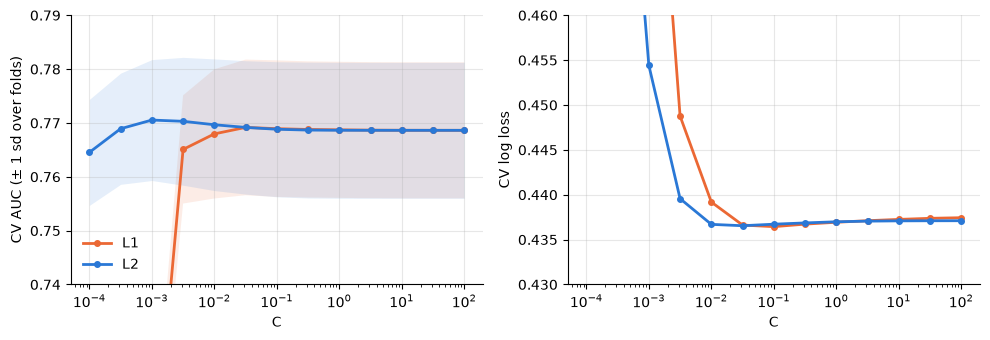

In [6]:
colours = {"L2": "#2a78d6", "L1": "#eb6834"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
for penalty, d in cv_res.groupby("penalty"):
    ax1.plot(d["C"], d["auc"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
    ax1.fill_between(d["C"], d["auc"] - d["auc_sd"], d["auc"] + d["auc_sd"],
                     color=colours[penalty], alpha=0.12, lw=0)
    ax2.plot(d["C"], d["logloss"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
ax1.set(xscale="log", xlabel="C", ylabel="CV AUC (± 1 sd over folds)", ylim=(0.74, 0.79))
ax2.set(xscale="log", xlabel="C", ylabel="CV log loss", ylim=(0.43, 0.46))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax1.legend(frameon=False)
plt.tight_layout()

Pick best C per penalty by CV log loss, refit on all of train, check on validation.

In [7]:
best = cv_res.loc[cv_res.groupby("penalty")["logloss"].idxmin()]
print(best.round(4).to_string(index=False), "\n")

models = {}
for _, row in best.iterrows():
    l1_ratio = 1 if row["penalty"] == "L1" else 0
    m = LogisticRegression(C=row["C"], l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
    m.fit(X_train, y_train)
    models[row["penalty"]] = m
    score(f"{row['penalty']} C={row['C']:.3g}", m.predict_proba(X_val)[:, 1])

# which features did L1 drop?
coefs = pd.Series(models["L1"].coef_[0], index=X_train.columns)
print(f"\nL1 kept {(coefs != 0).sum()} of {len(coefs)}; dropped:", list(coefs[coefs == 0].index))

penalty      C    auc  auc_sd  logloss
     L1 0.1000 0.7689  0.0127   0.4364
     L2 0.0316 0.7692  0.0124   0.4365 

L1 C=0.1               AUC 0.7782   log loss 0.4285   acc 0.8251
L2 C=0.0316            AUC 0.7783   log loss 0.4284   acc 0.8251

L1 kept 44 of 50; dropped: ['BILL_AMT2', 'PAY_5_-2', 'PAY_5_0', 'PAY_5_1', 'PAY_6_0', 'PAY_6_1']


### What we have seen so far

1. Logistic regression is clearly an improvement over just predicting the base rate for everyone. AUC goes from 0.5 to
   0.778 and log loss decreases from 0.528 to 0.428.
2. Accuracy is an inappropriate metric for the data. Note if we were to just predict that nobody defaults then
   we immediately get 77.9% accuracy (Lawson, 2026, 01.2).
3. Regularisation makes relatively little difference, which is in some way reassuring; this implies that we were
   not previously overfitting on the training data.
4. One possible limit is the sigmoid curve itself, i.e. the linear decision boundary. `03-SVM` tests this with a
   non-linear kernel.

## 3. Investigating the limits of the current model

### Learning curve

Would more data help? Train vs CV AUC as the training set grows.

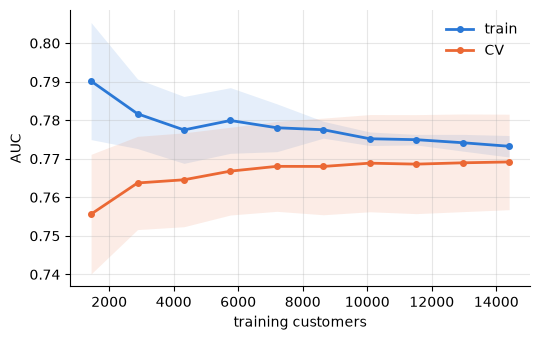

In [8]:
final = models["L2"]        # L2, C=0.0316 from above
sizes, auc_tr, auc_cv = learning_curve(final, X_train, y_train, cv=cv, scoring="roc_auc",
                                       train_sizes=np.linspace(0.1, 1, 10),
                                       shuffle=True, random_state=2026)   # rows are in ID order, see check below

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name, s, c in [("train", auc_tr, "#2a78d6"), ("CV", auc_cv, "#eb6834")]:
    ax.plot(sizes, s.mean(1), "o-", color=c, lw=2, ms=4, label=name)
    ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=0.12, lw=0)
ax.set(xlabel="training customers", ylabel="AUC")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

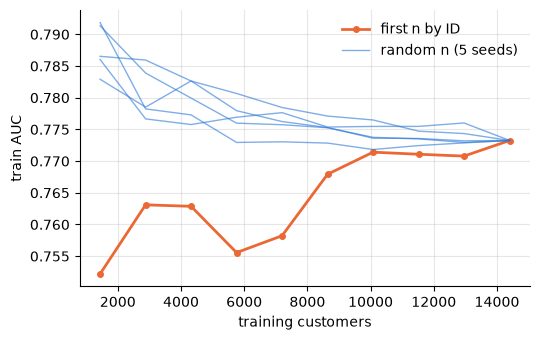

In [9]:
# check: without shuffle, each subset is the first n customers by ID; with shuffle, a random n
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for seed in [None, 0, 1, 2, 3, 4]:
    kw = {} if seed is None else {"shuffle": True, "random_state": seed}
    sz, tr, _ = learning_curve(final, X_train, y_train, cv=cv, scoring="roc_auc",
                               train_sizes=np.linspace(0.1, 1, 10), **kw)
    if seed is None:
        ax.plot(sz, tr.mean(1), "o-", color="#eb6834", lw=2, ms=4, label="first n by ID")
    else:
        ax.plot(sz, tr.mean(1), color="#2a78d6", lw=1, alpha=0.6,
                label="random n (5 seeds)" if seed == 0 else None)
ax.set(xlabel="training customers", ylabel="train AUC")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

### What this shows

Train and CV converge at ~0.77 and the CV line flattens, so more data would not give a significant increase in
performance. The model does appear to be too simple (Lawson, 2026, 02.2).

The dip in the unshuffled train curve is not noise. Data is in ID order, so it trained on the lowest IDs only.
With random subsets (5 seeds) there is no dip.

## 4. Increasing model complexity by introducing more features

Same 5-fold CV and same model (L2, C=0.0316) for every feature set; validation untouched.

In [10]:
results, fold_auc = {}, {}             # name -> CV summary; name -> AUC on each fold

def cv_features(name, make=None):
    """5-fold CV of the tuned L2 model on prep's fixes plus any extra columns from make(raw)."""
    X = raw_train if make is None else make(raw_train.copy())
    X = prep.prepare(X)                                      # fixes 1-3: fixed rules, nothing learned
    model = make_pipeline(StandardScaler(), clone(final))    # fix 4 learned inside each fold
    r = cross_validate(model, X, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
    fold_auc[name] = r["test_roc_auc"]
    results[name] = {"n": X.shape[1],
                     "auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std(),
                     "logloss": -r["test_neg_log_loss"].mean()}
    return pd.DataFrame.from_dict(results, orient="index").round(4)

cv_features("base")

,n,auc,auc_sd,logloss
base,50,0.769,0.0125,0.4367


We will now use the above function to test the introduction of new features. We start from the raw data
(log has not been applied yet), then add in the new features and then apply the cleanup from `prep.py`. We then
test for any potential improvement in the model via CV.

### Ratio features

Both are standard variables in credit scoring (Thomas, Crook & Edelman, 2017).

- Utilisation = bill / credit limit, each of the 6 months. How close to their limit someone is.
- Pay ratio = payment / previous month's bill, clipped to [0, 1]. Did they pay it off or just the minimum? Set to
  1 if nothing was owed.

In [11]:
def add_util(df):
    for k in range(1, 7):
        df[f"UTIL_{k}"] = (df[f"BILL_AMT{k}"] / df["LIMIT_BAL"]).clip(upper=1.5)   # a few go up to ~10
    return df

def add_payratio(df):
    for k in range(1, 6):
        bill, paid = df[f"BILL_AMT{k+1}"], df[f"PAY_AMT{k}"]      # PAY_AMTk pays last month's bill
        df[f"PAYRATIO_{k}"] = (paid / bill).where(bill > 0, 1).clip(0, 1)   # nothing owed -> 1
    return df

cv_features("+ utilisation", add_util)
cv_features("+ pay ratio", add_payratio)
cv_features("+ both", lambda df: add_payratio(add_util(df)))

,n,auc,auc_sd,logloss
base,50,0.7690,0.0125,0.4367
+ utilisation,56,0.7717,0.0140,0.4361
+ pay ratio,55,0.7707,0.0129,0.4360
+ both,61,0.7722,0.0140,0.4358


In [12]:
def compare(ref="base"):
    """AUC gain over `ref`, fold by fold: every feature set sat the same 5 folds."""
    gain = pd.DataFrame(fold_auc).sub(fold_auc[ref], axis=0)
    return pd.DataFrame({"mean gain": gain.mean(), "folds better": (gain > 0).sum()}).round(4)

compare()

,mean gain,folds better
base,0.0000,0
+ utilisation,0.0027,4
+ pay ratio,0.0017,5
+ both,0.0032,5


### Trends across the 6 months

We also consider:
- Linear trends (months late, change in utilisation). These are sums/differences of columns the model already
  has, so LR can already build them and thus minimal gain in performance is epected.
- Summaries (worst month, current late streak, max and spread of utilisation, months paid off). These are not linear in
  the existing columns, so they could add something.

In [13]:
STATUS = [f"PAY_{k}" for k in range(1, 7)]        # month 1 = most recent
UTIL = [f"UTIL_{k}" for k in range(1, 7)]
PAYRATIO = [f"PAYRATIO_{k}" for k in range(1, 6)]

def add_linear_trends(df):
    df = add_payratio(add_util(df))
    df["N_LATE"] = (df[STATUS] >= 1).sum(axis=1)                 # months late out of 6
    df["UTIL_CHANGE"] = df["UTIL_1"] - df["UTIL_6"]              # utilisation rising?
    return df

def add_summaries(df):
    df = add_payratio(add_util(df))
    late = df[STATUS] >= 1
    df["MAX_STATUS"] = df[STATUS].max(axis=1).clip(upper=3)      # worst month
    df["LATE_STREAK"] = late.cumprod(axis=1).sum(axis=1)         # months late in a row, counting back from now
    df["UTIL_MAX"] = df[UTIL].max(axis=1)
    df["UTIL_SD"] = df[UTIL].std(axis=1)                         # how much utilisation jumps around
    df["N_FULLPAY"] = (df[PAYRATIO] >= 1).sum(axis=1)            # months the bill was paid off
    return df

cv_features("+ both + linear trends", add_linear_trends)
cv_features("+ both + summaries", add_summaries)

,n,auc,auc_sd,logloss
base,50,0.7690,0.0125,0.4367
+ utilisation,56,0.7717,0.0140,0.4361
+ pay ratio,55,0.7707,0.0129,0.4360
+ both,61,0.7722,0.0140,0.4358
+ both + linear trends,63,0.7722,0.0140,0.4358
+ both + summaries,66,0.7731,0.0129,0.4347


In [14]:
compare("+ both")

,mean gain,folds better
base,-0.0032,0
+ utilisation,-0.0005,0
+ pay ratio,-0.0016,1
+ both,0.0000,0
+ both + linear trends,-0.0000,1
+ both + summaries,0.0009,3


### Decision

Keep the ratios ("+ both": 0.7722, better than base on 5/5 folds). Drop the trends covariates: linear trends add nothing
(LR can already build them), and the summaries give +0.0009 on only 3/5 folds, which isn't worth 5 extra
columns.

## 5. Final model

In [15]:
# C was tuned without the ratios; re-check it with them (same folds, scaling inside each fold)
X_ratio = prep.prepare(raw_train, ratios=True)

rows = []
for C in np.logspace(-3, 0, 7):
    model = make_pipeline(StandardScaler(), clone(final).set_params(C=C))
    r = cross_validate(model, X_ratio, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
    rows.append({"C": C, "auc": r["test_roc_auc"].mean(), "logloss": -r["test_neg_log_loss"].mean()})

tune = pd.DataFrame(rows)
best_C = tune.loc[tune["logloss"].idxmin(), "C"]
print(f"best C = {best_C:.3g}")
tune.round(4)

best C = 0.0316


,C,auc,logloss
0,0.0010,0.7744,0.4531
1,0.0032,0.7737,0.4385
2,0.0100,0.7729,0.4358
3,0.0316,0.7722,0.4358
4,0.1000,0.7719,0.4360
5,0.3162,0.7717,0.4362
6,1.0000,0.7717,0.4364


In [16]:
# final model: L2 + ratios, fitted on train only; validation as a check (test is scored in 08)
Xf_train, Xf_val = prep.transform(raw_train, raw_val, ratios=True)

final_model = clone(final).set_params(C=best_C).fit(Xf_train, y_train)
score("logistic (default)", preds["logistic (default)"])
score(f"L2 + ratios C={best_C:.3g}", final_model.predict_proba(Xf_val)[:, 1])

logistic (default)     AUC 0.7780   log loss 0.4284   acc 0.8248
L2 + ratios C=0.0316   AUC 0.7816   log loss 0.4267   acc 0.8243


### What this shows

C was tuned before the ratios were added, so we re-checked it with them. Best is still C=0.0316 by CV log loss,
and the curve is flat between 0.01 and 0.1, so the exact value barely matters.

This gives our final logistic regression model to be:

 L2, C=0.0316, 61 features (the 50 from fixes 1–4 + 6 utilisation + 5 pay ratio), fitted on train
only. The gain from the ratios holds up on validation, which played no part in choosing them: AUC 0.778 → 0.782,
log loss 0.428 → 0.427.

### Coefficients

What is the model using? (final model, features standardised)

,coef,odds ratio,coef without ratios
PAY_1_2,0.405,1.499,0.435
PAY_1_0,-0.380,0.684,-0.346
PAYRATIO_2,-0.152,0.859,NaN
PAY_4_0,-0.142,0.868,-0.039
EDUCATION_4,-0.142,0.868,-0.140
PAY_AMT2,-0.134,0.874,-0.182
PAY_1_3,0.129,1.137,0.140
LIMIT_BAL,-0.126,0.881,-0.181
PAY_AMT3,-0.106,0.899,-0.126
PAYRATIO_3,-0.105,0.900,NaN


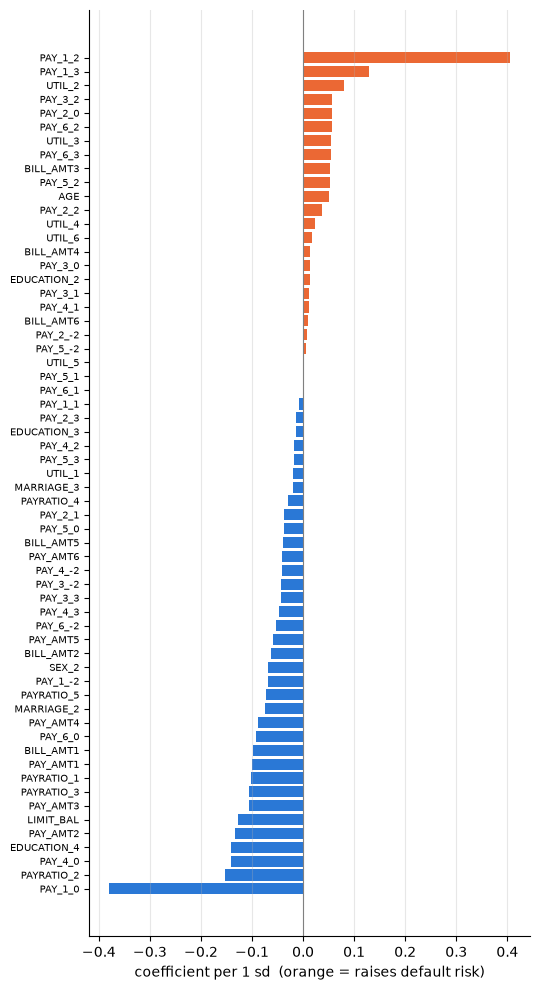

In [17]:
coef_f = pd.Series(final_model.coef_[0], index=Xf_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(5.5, 10))
ax.barh(coef_f.index, coef_f, color=np.where(coef_f > 0, "#eb6834", "#2a78d6"))
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="coefficient per 1 sd  (orange = raises default risk)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# 12 largest effects, next to the same column in the model without ratios (blank = new column)
coef = pd.Series(final.coef_[0], index=X_train.columns)
top_f = coef_f.reindex(coef_f.abs().sort_values(ascending=False).index)[:12]
pd.DataFrame({"coef": top_f, "odds ratio": np.exp(top_f),
              "coef without ratios": coef.reindex(top_f.index)}).round(3)

### Reading the coefficients

Logistic regression is a GLM with a logit link, so the linear predictor is on the log-odds scale (Cho, 2026,
§9, §13.1):

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_{61} x_{61}$$

- $\beta_j > 0$ raises the risk of default, $\beta_j < 0$ lowers it.
- $e^{\beta_j}$ is an odds ratio: the factor the odds of default are multiplied by per unit of $x_j$, holding the
  other features fixed.
- Because the features are standardised, one unit = 1 sd. So the coefficients are on a common scale and can be
  compared directly. Without this, a coefficient on LIMIT_BAL (log NT$) and one on AGE (years) would not be
  comparable.
- Caveat for 0/1 dummies: "per 1 sd" is less natural. To get the effect vs the reference category, use
  $\beta_j / \text{sd}_j$. E.g. `PAY_1_2`: sd ≈ 0.284, so $0.405 / 0.284 ≈ 1.43$ and $e^{1.43} ≈ 4.2$. Being 2
  months late multiplies the odds of default by ~4.2 vs paying in full.

It's worth noting here the meaning behind a coefficient in logistic regression. The exponential of the
coefficient shows the multiplicative change in the odds when that covariate moves by one unit - **with all other
covariates fixed**. This is answering a fundamentally different question to partitioning the raw data via a
covariate, thus we have to be slightly careful in how we interpret the coefficients. In our case, having even two
customers who are identical in all but one covariate is very unlikely. Therefore it is important to read groups
of closely linked covariates together (e.g. the six months of repayment status, or the six bill amounts), rather
than reading too much into any single coefficient. For example, partitioning the raw data by `PAY_1_2` gives odds
of default about 10 times higher for customers 2 months late than for those who paid in full (69% vs 18%), but
the model only attributes ×4.2 to `PAY_1_2` itself.

### What changed with the ratios

- Recent repayment status still dominates: `PAY_1_2` and `PAY_1_0` are still the two largest effects.
- Three pay-ratio columns are in the top 12. Paying more of the bill off lowers the risk of default, which is
  information the raw amounts weren't giving the model.
- The raw payment and limit coefficients shrank (PAY_AMT2 −0.18 → −0.13, LIMIT_BAL −0.18 → −0.13). The ratios
  are built from those amounts, so they now share the credit.
- `PAY_4_0` grew from −0.04 to −0.14 even though nothing about it changed. This is the "all other covariates
  fixed" point from above: a coefficient's meaning depends on what else is in the model, so we read groups of
  linked covariates together.

### How well is the model calibrated

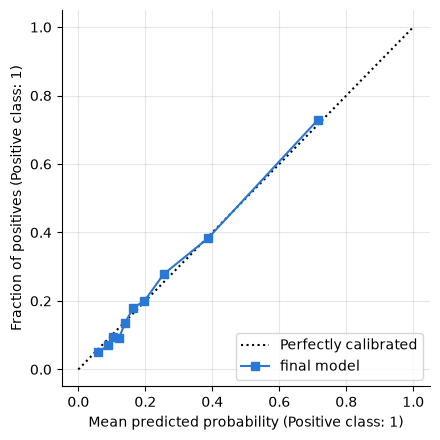

In [18]:
p_val = final_model.predict_proba(Xf_val)[:, 1]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
CalibrationDisplay.from_predictions(y_val, p_val, n_bins=10, strategy="quantile",   # 10 bins of ~600 customers
                                    ax=ax, name="final model", color="#2a78d6")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### What this shows

- Points sit almost on the diagonal: top bin predicts 71%, 73% actually default. So the probabilities can be
  taken at face value.
- Calibration ≠ AUC. AUC only checks ranking; this checks the numbers themselves.
- Most predictions are below 0.25, hence quantile bins (~600 customers each).
- Slight over-prediction around 0.1, but by at most 3 pts.
- Expected for LR: max likelihood = minimising log loss (Cho, 2026, §13.4).

## Summary

Logistic regression gives a clear improvement over the base rate, and accuracy turned out to be a misleading
metric for this data. Regularisation doesn't change much, and the learning curve shows that logistic regression
is too simple for the data. The model is well calibrated. Adding two ratios as covariates (utilisation and pay
ratio) marginally improved performance. We haven't played around with the threshold here, but since this would
not impact the AUC or log loss, we are happy to move on to SVMs.

For the SVM, it is worth bringing in the ratios. If the limit here is the linear boundary, an SVM with a kernel
should be able to learn a better non-linear one; `03-SVM` tests this. The final model is scored on the test set
in `07`.

## References

- Cho, H. (2026). *Linear and Generalised Linear Models* (MATH30013), lecture notes. University of Bristol.
- Lawson, D. (2026). *Data Science Toolbox* (MATHM0029), lectures 01.2 Introduction to Classification and 02.2
  Cross Validation. University of Bristol. https://dsbristol.github.io/dst/
- Maullin, T. (2026). *MATH30028: Statistical Machine Learning Part I*, lecture notes (last updated 15 Jan 2026).
  University of Bristol.
- Thomas, L. C., Crook, J. N. & Edelman, D. B. (2017). *Credit Scoring and Its Applications* (2nd ed.). SIAM.
  https://doi.org/10.1137/1.9781611974560
- Yeh, I-C. & Lien, C-H. (2009). The comparisons of data mining techniques for the predictive accuracy of
  probability of default of credit card clients. *Expert Systems with Applications* 36(2), 2473–2480.
  https://doi.org/10.1016/j.eswa.2007.12.020